Plotting the processed data to visualize the steps.

Author: Tayler LaSharr

Date: September 2024

Read in libraries and the data we care about.

In [33]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
import os
import re
from datetime import datetime

# Define the directories for AZ and WY
base_dir = r'H:\My Drive\DroughtSurfing'
locations = ['WY', 'AZ', 'UT']
# locations = ['UT', 'AZ']

# Define file paths for the exported GeoTIFFs within each directory
ndvi_file_names = [
    'modis_ndvi.tif',
    'modis_ndvi_corrected.tif',
    'modis_ndvi_filtered.tif',
    'smoothed_ndvi.tif'
]

ndvi_scaled_names = [
    'scaled_ndvi.tif'
]


Functions for plotting.

In [34]:
## function to extract dates from the band names (assuming format: YYYY_MM_DD_NDVI)
def extract_dates(band_names):
    dates = []
    for name in band_names:
        
        ## extract the date part from the name using regex
        match = re.search(r'(\d{4}_\d{2}_\d{2})', name)
        if match:
            date_str = match.group(1)
            
            ## convert string to datetime object
            date_obj = datetime.strptime(date_str, '%Y_%m_%d')
            dates.append(date_obj)
    return dates

## function to read NDVI data and calculate the mean NDVI over time
def read_ndvi_data(ndvi_path):
    with rasterio.open(ndvi_path) as src:
        ndvi_data = src.read()  # read all bands (layers) in the stack
        band_names = src.descriptions  # retrieve layer names (should contain dates)
        dates = extract_dates(band_names)
        mean_ndvi = [np.nanmean(ndvi_data[i, :, :]) for i in range(ndvi_data.shape[0])]
    return dates, mean_ndvi



Plot the figures (both the unscaled and scaled)

C:\Users\tlasharr\AppData\Local\Temp\ipykernel_2836\2832253466.py:22: RuntimeWarning: Mean of empty slice
  mean_ndvi = [np.nanmean(ndvi_data[i, :, :]) for i in range(ndvi_data.shape[0])]


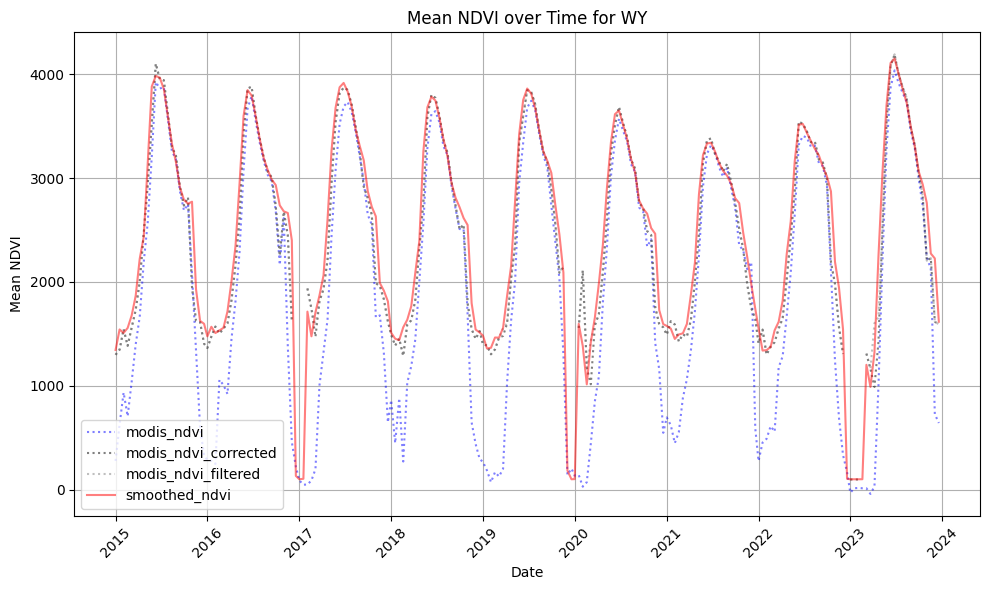

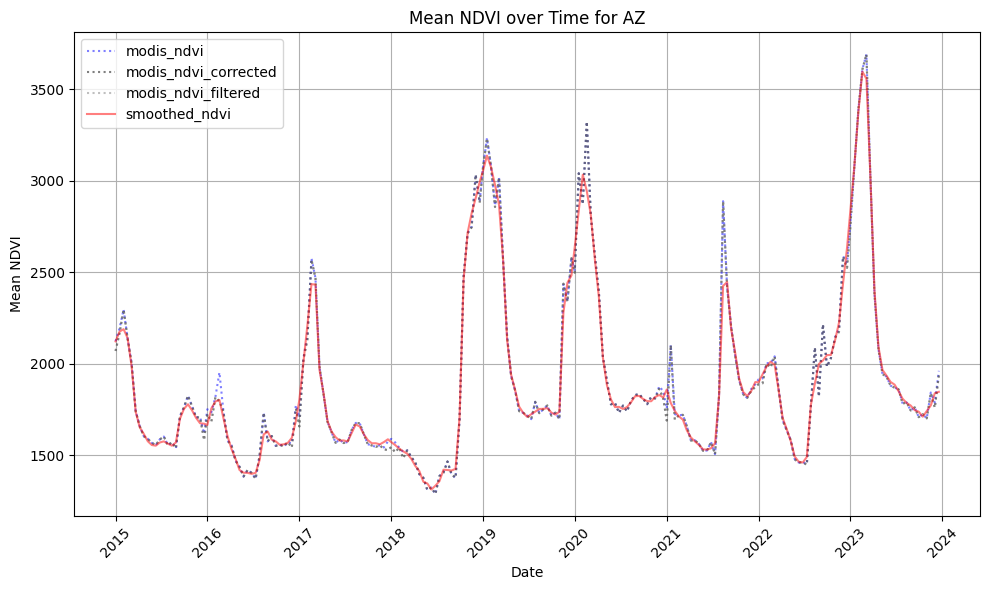

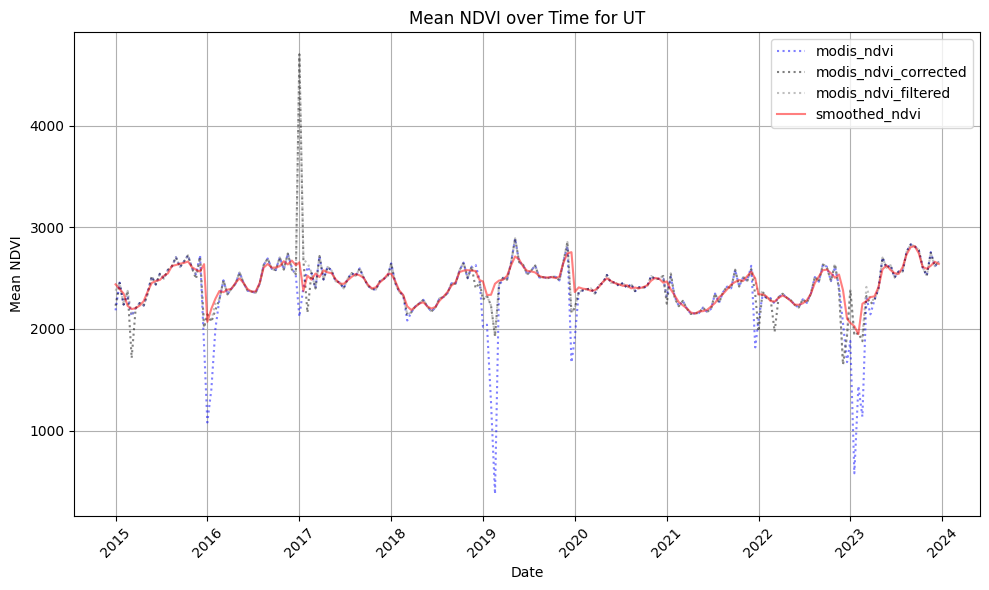

In [35]:
## plot each location (AZ and WY) on a separate plot
for location in locations:
    plt.figure(figsize=(10, 6))
    tiff_dir = os.path.join(base_dir, location)

    ## define colors and line styles for different NDVI products
    styles = [':', ':', ':', '-']
    colors = ['blue', 'black', 'gray', 'red']
    alphas = [0.5, 0.5, 0.5, 0.5]

    for i, file_name in enumerate(ndvi_file_names):
        ndvi_path = os.path.join(tiff_dir, file_name)
        dates, mean_ndvi = read_ndvi_data(ndvi_path)
        
        ## plot NDVI for each product in the same plot, different line styles
        plt.plot(dates, mean_ndvi, label=f"{file_name.replace('.tif', '')}", linestyle=styles[i], color = colors[i], alpha = alphas[i])

    ## add labels, title, and grid for each location
    plt.title(f'Mean NDVI over Time for {location}')
    plt.xlabel('Date')
    plt.ylabel('Mean NDVI')
    plt.legend(loc='best')
    plt.grid(True)
    plt.xticks(rotation=45)
    plt.tight_layout()

    ## show each plot separately
    plt.show()


# for location in locations:
#     plt.figure(figsize=(10, 6))
#     tiff_dir = os.path.join(base_dir, location)

#     ## define colors or line styles for different NDVI products
#     styles = [':', ':', ':', '-']
#     colors = ['blue', 'black', 'gray', 'red']
#     alphas = [0.5, 0.5, 0.5, 1]

#     for i, file_name in enumerate(ndvi_scaled_names):
#         ndvi_path = os.path.join(tiff_dir, file_name)
#         dates, mean_ndvi = read_ndvi_data(ndvi_path)
        
#         ## plot NDVI for each product in the same plot, different line styles
#         plt.plot(dates, mean_ndvi, label=f"{file_name.replace('.tif', '')}", linestyle=styles[i], color = colors[i], alpha = alphas[i])

#     ## add labels, title, and grid for each location
#     plt.title(f'Scaled NDVI over Time for {location}')
#     plt.xlabel('Date')
#     plt.ylabel('Mean NDVI')
#     plt.legend(loc='best')
#     plt.grid(True)
#     plt.xticks(rotation=45)
#     plt.tight_layout()

#     ## show each plot separately
#     plt.show()    